# Learner Early Warning
**ML Zoomcamp midterm · Agentic Labs Academy**

An Academy mentor has ten check-in slots. At the end of the first 14 course days,
can engagement alone help rank still-enrolled learners by their risk of withdrawing over the
following 30 days?

One row represents one eligible enrolment in the Open University's BBB module. This analysis
uses public OULAD records to test a prototype for a future Academy workflow. Run all cells
from the repository root after `uv sync --group notebook`.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve
from threadpoolctl import threadpool_limits

from data import FEATURES, KEY, TARGET, build_dataset
from download_data import ensure_data
from modeling import (
    OUTREACH_CAPACITY,
    SEED,
    baseline_scores,
    evaluate_models,
    ranking_metrics,
    split_cohorts,
    tune_models,
)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#293f50",
        "text.color": "#152f42",
        "axes.edgecolor": "#b6c7ce",
        "axes.titlepad": 10,
        "grid.color": "#dce6eb",
    }
)
teal, slate, rust = "#087c78", "#42647f", "#a65a3a"

## 1. Data and prediction timeline

[OULAD, UCI dataset 349](https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset)
contains course, registration, assessment and virtual learning environment records. We use
`courses.csv` to verify the horizon, `studentRegistration.csv` for eligibility and labels,
`studentVle.csv` for daily activity, and `studentInfo.csv` to identify withdrawals with a
missing date.

- **Days 0–13:** collect click counts and build features from two seven-day periods.
- **Start of day 14:** rank learners registered by day 13 who have yet to withdraw.
- **Days 14–43:** a recorded withdrawal is a positive outcome. Exclude records marked
  withdrawn when the date is missing, since timing cannot be determined. A known
  withdrawal after day 43 is outside the target window.
- Keep the earliest eligible enrolment for each person. Restrict inputs to activity:
  student IDs, course dates, demographics, grades and withdrawal outcomes stay out
  of the feature matrix.

Each CSV is joined by module, presentation and student ID. The click log is read in chunks.
Days with no recorded clicks are represented by zero, including fully inactive learners.

In [7]:
data_dir = ensure_data()
raw_columns = ["date_registration", "date_unregistration"]
raw_registrations = pd.read_csv(
    Path(data_dir) / "studentRegistration.csv",
    usecols=KEY + raw_columns,
    na_values=["?"],
)
raw_bbb = raw_registrations.loc[raw_registrations.code_module.eq("BBB")]
raw_date_checks = raw_bbb[raw_columns].agg(["min", "max"])
raw_date_checks.loc["missing"] = raw_bbb[raw_columns].isna().sum()
display(raw_date_checks)

dataset, audit = build_dataset(data_dir)
splits = split_cohorts(dataset)
analysis = pd.concat([splits.train, splits.validation, splits.test], ignore_index=True)
cohort_rollup = analysis.groupby("code_presentation")[TARGET].agg(
    rows="size",
    withdrawals="sum",
    rate="mean",
)
display(audit.join(splits.repeat_counts.rename("repeat_learner_exclusions")).round(3))
display(cohort_rollup.round(4))
print(f"Total rows used across the chronological splits: {len(analysis):,}")

,date_registration,date_unregistration
min,-322.0,-317.0
max,81.0,241.0
missing,9.0,5532.0


,raw_registrations,eligible,missing_registration_date,registered_after_cutoff,already_withdrawn,missing_withdrawal_date,withdrawn_in_window,zero_activity,withdrawal_rate,repeat_learner_exclusions
code_presentation,,,,,,,,,,
2013B,1767,1606,1,2,158,0,105,233,0.065,0
2013J,2237,1852,2,3,380,0,50,307,0.027,31
2014B,1613,1287,5,6,314,1,25,152,0.019,57
2014J,2292,1779,1,19,481,12,31,190,0.017,53


,rows,withdrawals,rate
code_presentation,,,
2013B,1606,105,0.0654
2013J,1821,49,0.0269
2014B,1230,24,0.0195
2014J,1726,30,0.0174


Total rows used across the chronological splits: 6,383


## 2. Exploratory data analysis

Inspect the feature ranges and zero counts. Compare the target and feature patterns using
the fitting intakes. The final intake's counts are shown for transparency and play no role
in selecting features, hyperparameters, or the model.

,count,mean,std,min,50%,90%,99%,max,missing,zeros
active_days_week_1,3427.0,2.07,1.93,0.0,2.0,5.0,7.00,7.0,0,890
active_days_week_2,3427.0,2.03,1.93,0.0,2.0,5.0,7.00,7.0,0,958
clicks_week_1,3427.0,48.61,86.45,0.0,22.0,122.0,386.92,1316.0,0,890
clicks_week_2,3427.0,39.69,72.24,0.0,19.0,98.0,319.18,1149.0,0,958
days_since_last_activity,3427.0,4.45,5.04,0.0,2.0,14.0,14.00,14.0,0,982


,active_days_week_1,active_days_week_2,clicks_week_1,clicks_week_2,days_since_last_activity
withdrew_in_30_days,,,,,
0,2.0,2.0,24.0,20.0,2.0
1,0.0,0.0,0.0,0.0,14.0


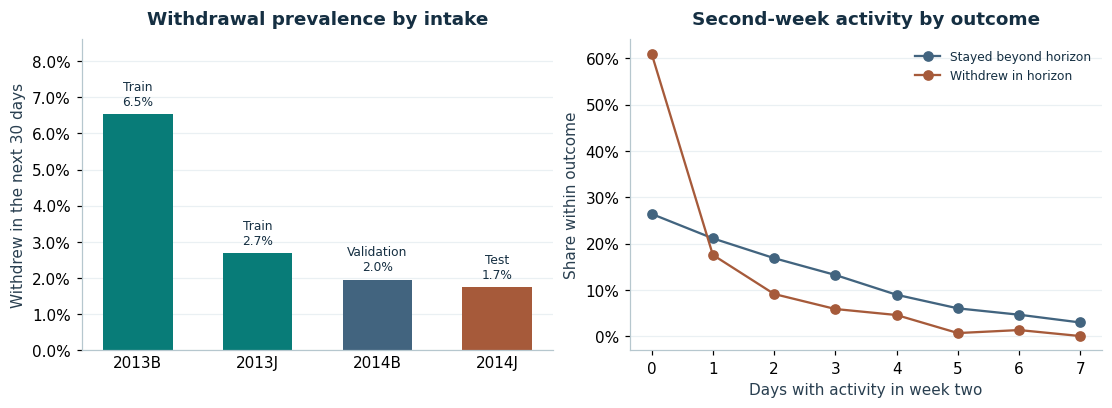

In [8]:
fitting = splits.train
feature_summary = fitting[FEATURES].describe(percentiles=[0.5, 0.9, 0.99]).T
feature_summary["missing"] = fitting[FEATURES].isna().sum()
feature_summary["zeros"] = fitting[FEATURES].eq(0).sum()
display(feature_summary.round(2))
display(fitting.groupby(TARGET)[FEATURES].median())

plots, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
roles = ["Train", "Train", "Validation", "Test"]
colors = [teal, teal, slate, rust]
bars = axes[0].bar(cohort_rollup.index, cohort_rollup["rate"], color=colors, width=0.58)
labels = [
    f"{role}\n{rate:.1%}"
    for role, rate in zip(roles, cohort_rollup["rate"], strict=True)
]
axes[0].bar_label(bars, labels=labels, padding=4, fontsize=8)
axes[0].set(
    title="Withdrawal prevalence by intake",
    ylabel="Withdrew in the next 30 days",
    ylim=(0, 0.086),
)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].tick_params(axis="x", length=0)
axes[0].grid(axis="y", alpha=0.6)
axes[0].set_axisbelow(True)

for outcome, label, color in [
    (0, "Stayed beyond horizon", slate),
    (1, "Withdrew in horizon", rust),
]:
    days = fitting.loc[fitting[TARGET].eq(outcome), "active_days_week_2"]
    proportions = days.value_counts(normalize=True).reindex(range(8), fill_value=0)
    axes[1].plot(proportions.index, proportions, marker="o", label=label, color=color)
axes[1].set(
    title="Second-week activity by outcome",
    xlabel="Days with activity in week two",
    ylabel="Share within outcome",
)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xticks(range(8))
axes[1].grid(axis="y", alpha=0.6)
axes[1].legend(frameon=False, fontsize=8)
plt.show()

A large share of the learners who withdrew had zero active days in week two. Some learners
who stayed beyond the horizon also had zero activity, so a binary inactivity rule creates
many ties. The base withdrawal rate falls across intakes. An accuracy score would hide that
change and could look strong even for a model that never prioritises a withdrawal.

## 3. Train and tune three models

Train on 2013B and 2013J, use 2014B to select hyperparameters and the model, and keep
2014J for a final check. Average precision (AP) measures how well the ranking finds the
rare positive cases across all thresholds. Higher AP wins and Brier score breaks exact ties.

Compare logistic regression on scaled log-count features, a random forest, and histogram
gradient boosting. Two practical reference rules rank learners by no activity in week two
and by days since last activity. They have no fitted parameters.

In [9]:
trials, best = tune_models(splits)
validation_baselines = pd.DataFrame(
    {
        name: ranking_metrics(splits.validation[TARGET], scores)
        for name, scores in baseline_scores(splits.validation[FEATURES]).items()
    }
).T
display(validation_baselines.round(4))
display(
    trials[
        ["model", "parameters", "average_precision", "roc_auc", "brier_score"]
    ].round(5)
)
print(f"Number of configurations evaluated: {len(trials)}")
print(f"Selected before opening the held-out intake: {trials.iloc[0]['model']}")

,average_precision,roc_auc,expected_hits_at_10,precision_at_10,recall_at_10
No activity in week two,0.0261,0.5909,0.3719,0.0372,0.0155
Days since last activity,0.0380,0.6450,0.6107,0.0611,0.0254


,model,parameters,average_precision,roc_auc,brier_score
0,Logistic regression,{'logisticregression__C': 30.0},0.04057,0.64492,0.01993
1,Logistic regression,{'logisticregression__C': 3.0},0.04053,0.64430,0.01993
2,Logistic regression,{'logisticregression__C': 0.3},0.03995,0.63808,0.01991
3,Logistic regression,{'logisticregression__C': 0.03},0.03918,0.62885,0.01985
4,Random forest,"{'max_depth': 3, 'min_samples_leaf': 25}",0.03676,0.60529,0.02001
5,Random forest,"{'max_depth': 3, 'min_samples_leaf': 8}",0.03667,0.60553,0.02000
6,Random forest,"{'max_depth': None, 'min_samples_leaf': 25}",0.03653,0.60512,0.02029
7,Gradient boosting,"{'l2_regularization': 3.0, 'max_iter': 60, 'ma...",0.03647,0.60164,0.02028
8,Random forest,"{'max_depth': None, 'min_samples_leaf': 8}",0.03617,0.60107,0.02067
9,Random forest,"{'max_depth': 6, 'min_samples_leaf': 25}",0.03588,0.59320,0.02019


Number of configurations evaluated: 18
Selected before opening the held-out intake: Logistic regression


## 4. Test on 2014J

Refit each model's validation-selected configuration using the training and validation
intakes. The exported model remains the validation winner. We report other models' test
scores for comparison after making that choice.

Expected hits at ten is the number of true withdrawals a mentor would expect among ten
check-ins. When a score tie straddles tenth place, it averages across equally ranked
candidates. Precision at ten is the expected hits divided by ten. The random shortlist
benchmark is ten multiplied by the held-out withdrawal rate.

,average_precision,roc_auc,expected_hits_at_10,precision_at_10,recall_at_10,brier_score
No activity in week two,0.0244,0.6098,0.3233,0.0323,0.0108,NaN
Days since last activity,0.0372,0.6808,0.5525,0.0552,0.0184,NaN
Logistic regression,0.0426,0.7105,0.5525,0.0552,0.0184,0.0175
Random forest,0.0450,0.7579,0.5525,0.0552,0.0184,0.0175
Gradient boosting,0.0382,0.6646,0.4972,0.0497,0.0166,0.0177


Held out: 1,726 learners with 30 withdrawals (1.74%).
Random shortlist: 0.17 expected withdrawals among ten.
Shipped model: Logistic regression.
AP: 0.0426.
Expected hits in the top ten: 0.55.


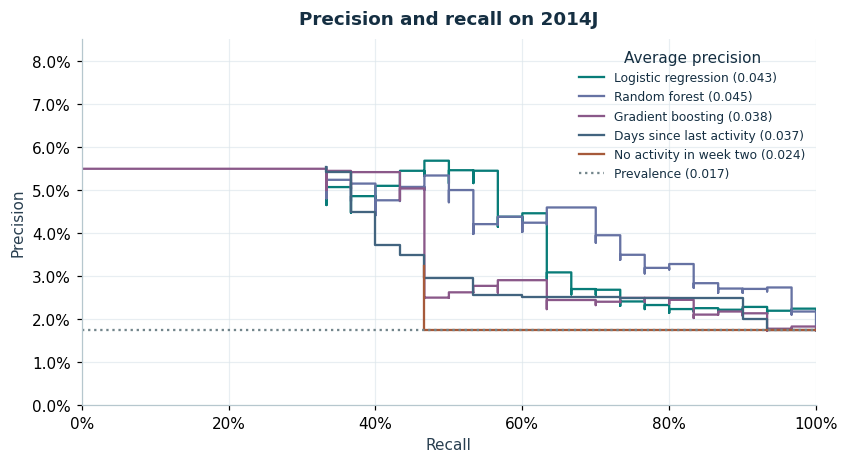

In [10]:
chosen, model, held_out, scores = evaluate_models(splits, best)
display(held_out.round(4))

y_test = splits.test[TARGET]
test_rate = y_test.mean()
print(
    f"Held out: {len(y_test):,} learners with {int(y_test.sum())} withdrawals ({test_rate:.2%})."
)
print(
    f"Random shortlist: {OUTREACH_CAPACITY * test_rate:.2f} expected withdrawals among ten."
)
print(f"Shipped model: {chosen}.")
print(f"AP: {held_out.loc[chosen, 'average_precision']:.4f}.")
print(
    f"Expected hits in the top ten: {held_out.loc[chosen, 'expected_hits_at_10']:.2f}."
)

fig, axe = plt.subplots(figsize=(7.6, 4.1), layout="constrained")
selected_series = [
    (chosen, teal),
    ("Random forest", "#6672a3"),
    ("Gradient boosting", "#8a5889"),
    ("Days since last activity", slate),
    ("No activity in week two", rust),
]
for name, color in selected_series:
    precision, recall, _ = precision_recall_curve(y_test, scores[name])
    ap = held_out.loc[name, "average_precision"]
    axe.step(
        recall[:-1],
        precision[:-1],
        where="post",
        label=f"{name} ({ap:.3f})",
        color=color,
    )
axe.axhline(
    test_rate, color="#72858b", linestyle=":", label=f"Prevalence ({test_rate:.3f})"
)
axe.set(
    xlim=(0, 1),
    ylim=(0, 0.085),
    title="Precision and recall on 2014J",
    xlabel="Recall",
    ylabel="Precision",
)
axe.yaxis.set_major_formatter(PercentFormatter(1))
axe.xaxis.set_major_formatter(PercentFormatter(1))
axe.grid(alpha=0.65)
axe.legend(title="Average precision", fontsize=8, frameon=False)
plt.show()

Logistic regression was selected on 2014B. On 2014J it beat the two rules on AP and
matched the days-since-last-activity rule at ten check-ins. Random forest had the highest
test AP and also matched that rule at ten. The expected hit count was below one for all
methods. There were 30 positive outcomes and many learners shared the same engagement pattern.

## 5. Inspect feature importance

Shuffle one feature at a time on the validation intake for the chosen training-only
estimator, then measure the change in AP over 30 repeats. Negative values mean shuffling
happened to improve AP. Correlated counts and recency can mask or redistribute importance.
This analysis is descriptive and does not drive another round of tuning.

,feature,mean_ap_drop,std_ap_drop
0,active_days_week_1,-0.00917,0.01329
1,active_days_week_2,-0.00749,0.00943
3,clicks_week_2,0.00049,0.00499
4,days_since_last_activity,0.00635,0.00693
2,clicks_week_1,0.00892,0.00503


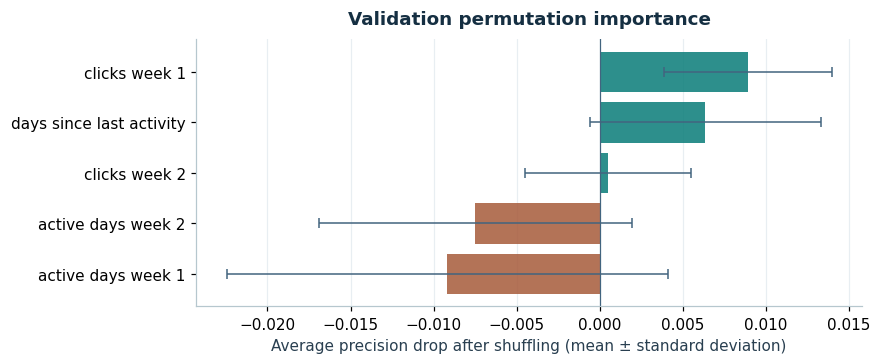

In [11]:
validation_estimator = best[chosen][0]
with threadpool_limits(limits=2):
    shuffled = permutation_importance(
        validation_estimator,
        splits.validation[FEATURES],
        splits.validation[TARGET],
        scoring="average_precision",
        n_repeats=30,
        random_state=SEED,
        n_jobs=1,
    )
feature_importance = pd.DataFrame(
    {
        "feature": FEATURES,
        "mean_ap_drop": shuffled.importances_mean,
        "std_ap_drop": shuffled.importances_std,
    }
).sort_values("mean_ap_drop")
display(feature_importance.round(5))

fig, axe = plt.subplots(figsize=(7.9, 3.2), layout="constrained")
labels = feature_importance["feature"].str.replace("_", " ")
axe.barh(
    labels,
    feature_importance["mean_ap_drop"],
    xerr=feature_importance["std_ap_drop"],
    color=[teal if drop >= 0 else rust for drop in feature_importance["mean_ap_drop"]],
    alpha=0.85,
    error_kw={"ecolor": slate, "capsize": 3, "linewidth": 1},
)
axe.axvline(0, color=slate, lw=0.8)
axe.set(
    title="Validation permutation importance",
    xlabel="Average precision drop after shuffling (mean ± standard deviation)",
)
axe.grid(axis="x", alpha=0.65)
axe.set_axisbelow(True)
plt.show()

## 6. What a mentor can do with the output

The FastAPI demo accepts a cohort's daily counts and returns a risk-ranked list. Scores
support human check-ins. The validation and test intakes come from a single UK distance
learning module, and missing log activity can reflect offline study or recording gaps.
An Academy evaluation would start by defining engagement and withdrawal events,
then compare the model with the recency rule at the team's actual outreach capacity.

Use `python train.py` to reproduce the model package and `reports/metrics.json`, then
follow the Docker commands in the README to serve the model.